### Identify outliers using IQR and Z-score methods by manually computing quartiles, standard deviations, and thresholds without using built-in statistical functions, and visualize them using a custom plotting approach.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
numerical = []

for column in df.columns:
    if df[column].dtype != "object":
        numerical.append(column)

print(numerical)

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [4]:
column = "age"

data = []

for value in df[column]:
    data.append(value)

data.sort()

print(data[:10])

[29, 34, 34, 35, 35, 35, 35, 37, 37, 38]


In [5]:
n = len(data)

q1 = data[n // 4]
q3 = data[(3 * n) // 4]

print("Q1:", q1)
print("Q3:", q3)

Q1: 47
Q3: 61


In [6]:
iqr = q3 - q1

print("IQR:", iqr)

IQR: 14


In [7]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print("Lower:", lower)
print("Upper:", upper)

Lower: 26.0
Upper: 82.0


In [8]:
iqr_outliers = []

for value in data:
    if value < lower or value > upper:
        iqr_outliers.append(value)

print("IQR Outliers:", iqr_outliers)

IQR Outliers: []


In [9]:
mean = sum(data) / len(data)

print("Mean:", mean)

Mean: 54.366336633663366


In [10]:
total = 0

for value in data:
    total += (value - mean) ** 2

variance = total / len(data)
std = variance ** 0.5

print("Standard Deviation:", std)

Standard Deviation: 9.067101638577874


In [11]:
z_scores = []

for value in data:
    z = (value - mean) / std
    z_scores.append(z)

print(z_scores[:10])

[-2.797623501399499, -2.24617936860998, -2.24617936860998, -2.1358905420520764, -2.1358905420520764, -2.1358905420520764, -2.1358905420520764, -1.915312888936269, -1.915312888936269, -1.805024062378365]


In [12]:
z_scores = []

for value in data:
    z = (value - mean) / std
    z_scores.append(z)

print(z_scores[:10])

[-2.797623501399499, -2.24617936860998, -2.24617936860998, -2.1358905420520764, -2.1358905420520764, -2.1358905420520764, -2.1358905420520764, -1.915312888936269, -1.915312888936269, -1.805024062378365]


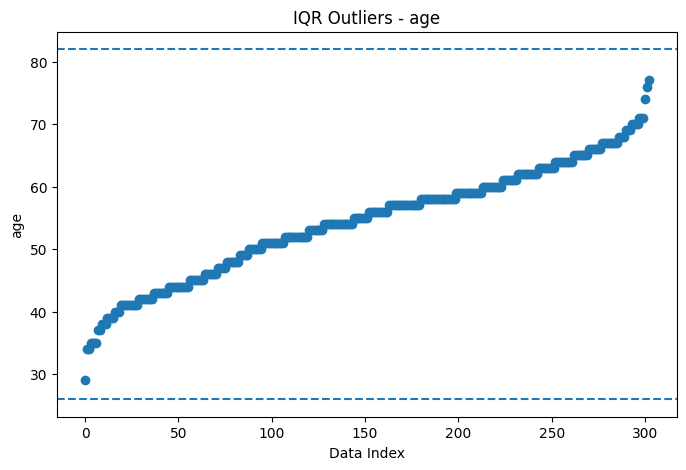

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(range(len(data)), data)

for i in range(len(data)):
    if data[i] in iqr_outliers:
        plt.scatter(i, data[i])

plt.axhline(lower, linestyle="--")
plt.axhline(upper, linestyle="--")

plt.xlabel("Data Index")
plt.ylabel(column)
plt.title("IQR Outliers - " + column)

plt.show()

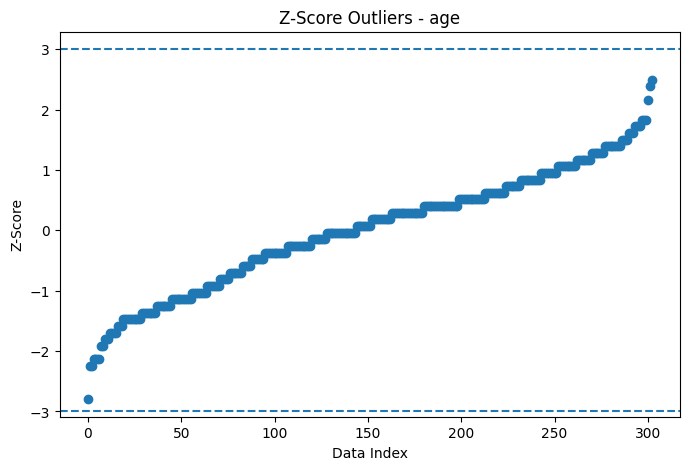

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Index")
plt.ylabel("Z-Score")
plt.title("Z-Score Outliers - " + column)

plt.show()

In [16]:
z_outliers = []

for i in range(len(data)):
    if abs(z_scores[i]) > 3:
        z_outliers.append(data[i])

print("Z-Score Outliers:", z_outliers)

Z-Score Outliers: []


In [17]:
print("IQR Outliers:", len(iqr_outliers))
print("Z-Score Outliers:", len(z_outliers))

IQR Outliers: 0
Z-Score Outliers: 0


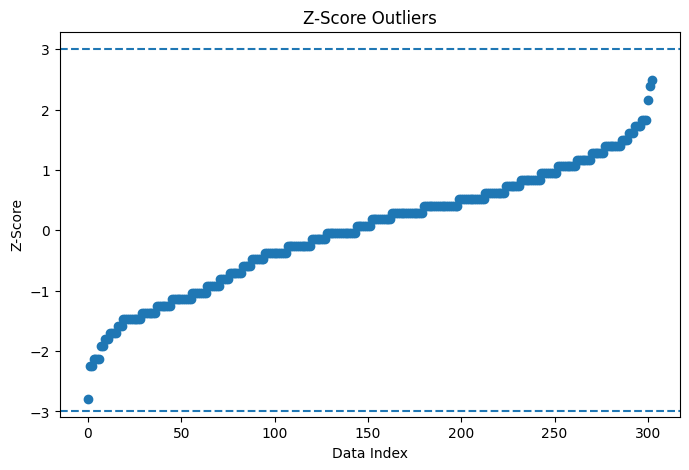

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Index")
plt.ylabel("Z-Score")
plt.title("Z-Score Outliers")

plt.show()